# Chapter 32: The Speedometer Meets the Odometer

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** see why one accumulated quantity keeps direction (where you ended up) while the other records every bit of movement (how far you went). We follow a two-block trip, then the idea behind the Fundamental Theorem of Calculus, then a velocity that changes direction.

The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to run a cell, change a number and see what happens: nothing here can break.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

NAVY, TEAL, GOLD, PINK, INK, GREY = "#1f3a5f", "#1b8a8a", "#d9a21b", "#c0467a", "#222222", "#888888"

def g(x, digits=4):
    """Format a number without trailing zeros."""
    s = f"{x:.{digits}f}".rstrip("0").rstrip(".")
    return "0" if s in ("-0", "") else s

def par(x):
    """Wrap negative numbers in parentheses, for substitution chains."""
    s = g(x)
    return f"({s})" if s.startswith("-") else s

def new_fig(w=7, h=4):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.grid(alpha=0.25)
    return fig, ax

## Demonstration 1: Two ledgers for one trip

**Question.** The traveler moves 5 units. Why do they end only 1 unit from the start?

$$+3 + (-2) = +1\ \text{unit} \qquad\qquad |{+3}| + |{-2}| = 3 + 2 = 5\ \text{units}$$

- Velocity is signed: $+$ means the positive direction, $-$ the negative one.
- The bars $|\ |$ give the size without the sign.
- $s(t)$ is position, in units. The traveler starts at $s(0) = 10$.
- Each block lasts one time unit, so each block's change equals its velocity.

**Predict first:** make the second velocity $-3$. What are the displacement and the distance?

Starting values: velocities $+3$ then $-2$, start 10.

In [2]:
v1, v2, start = 3, -2, 10
disp = v1 + v2
dist = abs(v1) + abs(v2)
print(f"Displacement: +{v1} + ({v2}) = {disp:+d} unit")
print(f"Distance: |+{v1}| + |{v2}| = {abs(v1)} + {abs(v2)} = {dist} units")
print(f"Ending position: s(2) = {start} + {disp} = {start + disp} units")
print(f"Position path: {start} -> {start + v1} -> {start + v1 + v2}")
print(f"Wrong way (adding distance to the start): {start} + {dist} = {start + dist}")
print()
print("All menu states:")
for s0 in (10, 0):
    for vv in (-3, -2, 0, 2):
        d = 3 + vv
        print(f"  start {s0:>2}, second velocity {par(vv):>4}: displacement 3 + {par(vv)} = {d}, distance 3 + {abs(vv)} = {3 + abs(vv)}, end {s0} + {d} = {s0 + d}")

Displacement: +3 + (-2) = +1 unit
Distance: |+3| + |-2| = 3 + 2 = 5 units
Ending position: s(2) = 10 + 1 = 11 units
Position path: 10 -> 13 -> 11
Wrong way (adding distance to the start): 10 + 5 = 15

All menu states:
  start 10, second velocity (-3): displacement 3 + (-3) = 0, distance 3 + 3 = 6, end 10 + 0 = 10
  start 10, second velocity (-2): displacement 3 + (-2) = 1, distance 3 + 2 = 5, end 10 + 1 = 11
  start 10, second velocity    0: displacement 3 + 0 = 3, distance 3 + 0 = 3, end 10 + 3 = 13
  start 10, second velocity    2: displacement 3 + 2 = 5, distance 3 + 2 = 5, end 10 + 5 = 15
  start  0, second velocity (-3): displacement 3 + (-3) = 0, distance 3 + 3 = 6, end 0 + 0 = 0
  start  0, second velocity (-2): displacement 3 + (-2) = 1, distance 3 + 2 = 5, end 0 + 1 = 1
  start  0, second velocity    0: displacement 3 + 0 = 3, distance 3 + 0 = 3, end 0 + 3 = 3
  start  0, second velocity    2: displacement 3 + 2 = 5, distance 3 + 2 = 5, end 0 + 5 = 5


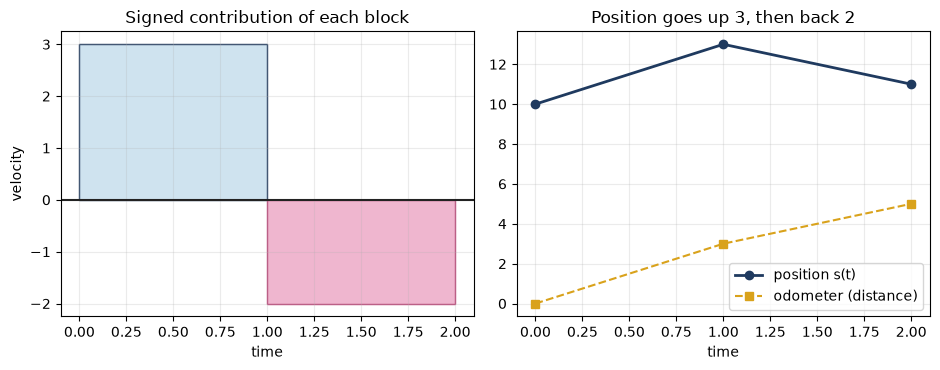

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
a1.bar([0.5], [3], width=1, fc="#cfe3ef", ec=NAVY); a1.bar([1.5], [-2], width=1, fc="#efb6cf", ec=PINK)
a1.axhline(0, color=INK); a1.set_title("Signed contribution of each block"); a1.set_xlabel("time"); a1.set_ylabel("velocity")
a1.grid(alpha=0.25)
a2.plot([0, 1, 2], [10, 13, 11], "o-", color=NAVY, lw=2, label="position s(t)")
a2.plot([0, 1, 2], [0, 3, 5], "s", ls="dashed", color=GOLD, label="odometer (distance)")
a2.set_xlabel("time"); a2.set_title("Position goes up 3, then back 2"); a2.legend(); a2.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**What this shows.** The left picture shows each block's signed contribution. The right picture follows position: up 3, then back 2. The odometer adds every movement as positive. To find where something ends up, add signed changes to the start. To find how much it moved, add sizes. Never add distance to the start.

**Where it stops working.** This assumes constant velocity on each block and one straight line of motion. A coordinate direction is picked before you start; flipping it flips every sign but not the distance.

## Demonstration 2: Accumulation stores the rate in its slope

**Question.** If $A(x)$ is the area so far, how fast does $A$ grow as $x$ moves?

$$A'(x) = f(x)$$

- $f(t) = 2t + 1$ is a continuous rate.
- $A(x)$ is the area under it from 0 to $x$ (a trapezoid, so $A(x) = x(1 + f(x))/2 = x^2 + x$).
- $h$ is a small step to the right, and the strip is the area it adds.

**Predict first:** at $x = 2$, shrink $h$ from 1 to 0.1. What number does strip $/ h$ approach?

Starting values: $x = 2$, $h = 0.5$.

In [4]:
f = lambda t: 2*t + 1
A = lambda x: x*(1 + f(x))/2
x, h = 2, 0.5
print(f"A({x}) = {x} x (1 + {f(x)}) / 2 = {g(A(x))}")
print(f"A({g(x+h)}) = {g(x+h)} x (1 + {g(f(x+h))}) / 2 = {g(A(x+h))}")
print(f"Added strip: A({g(x+h)}) - A({x}) = {g(A(x+h))} - {g(A(x))} = {g(A(x+h) - A(x))}")
print(f"Strip / h = {g(A(x+h) - A(x))} / {g(h)} = {g((A(x+h) - A(x))/h)}")
print(f"f({x}) = 2 x {x} + 1 = {f(x)}")
print(f"Gap from f(x): {g((A(x+h) - A(x))/h - f(x))}  (exactly h)")
print()
print("All menu states:")
for xx in (1, 2):
    for hh in (1, 0.5, 0.1):
        st = A(xx + hh) - A(xx)
        print(f"  x = {xx}, h = {g(hh):>3}: A({xx}) = {g(A(xx))}, A({g(xx+hh)}) = {g(A(xx+hh))}, strip {g(st)}, strip/h = {g(st/hh)}, f({xx}) = {f(xx)}")

A(2) = 2 x (1 + 5) / 2 = 6
A(2.5) = 2.5 x (1 + 6) / 2 = 8.75
Added strip: A(2.5) - A(2) = 8.75 - 6 = 2.75
Strip / h = 2.75 / 0.5 = 5.5
f(2) = 2 x 2 + 1 = 5
Gap from f(x): 0.5  (exactly h)

All menu states:
  x = 1, h =   1: A(1) = 2, A(2) = 6, strip 4, strip/h = 4, f(1) = 3
  x = 1, h = 0.5: A(1) = 2, A(1.5) = 3.75, strip 1.75, strip/h = 3.5, f(1) = 3
  x = 1, h = 0.1: A(1) = 2, A(1.1) = 2.31, strip 0.31, strip/h = 3.1, f(1) = 3
  x = 2, h =   1: A(2) = 6, A(3) = 12, strip 6, strip/h = 6, f(2) = 5
  x = 2, h = 0.5: A(2) = 6, A(2.5) = 8.75, strip 2.75, strip/h = 5.5, f(2) = 5
  x = 2, h = 0.1: A(2) = 6, A(2.1) = 6.51, strip 0.51, strip/h = 5.1, f(2) = 5


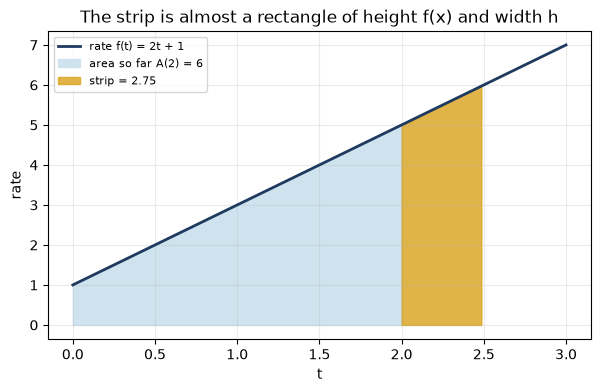

In [5]:
ts = np.linspace(0, 3, 100)
x, h = 2, 0.5
fig, ax = new_fig(7, 4)
ax.plot(ts, f(ts), color=NAVY, lw=2, label="rate f(t) = 2t + 1")
m = ts <= x
ax.fill_between(ts[m], 0, f(ts[m]), color="#cfe3ef", label=f"area so far A({x}) = {g(A(x))}")
m2 = (ts >= x) & (ts <= x + h)
ax.fill_between(ts[m2], 0, f(ts[m2]), color=GOLD, alpha=0.8, label=f"strip = {g(A(x+h)-A(x))}")
ax.set_xlabel("t"); ax.set_ylabel("rate"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("The strip is almost a rectangle of height f(x) and width h"); plt.show()

**What this shows.** The new strip is almost a rectangle of height $f(x)$ and width $h$. Dividing its area by $h$ leaves a number near $f(x)$; for this straight line the extra is exactly $h$. So as $h$ shrinks, the growth rate of the running total becomes $f(x)$. When you know a running total, its rate of growth at a moment is the rate being accumulated at that moment.

**Where it stops working.** This needs a continuous rate on an interval starting at 0. The gap is exactly $h$ here only because the rate is a straight line; for a curve the gap is not that tidy, but it still shrinks.

## Demonstration 3: Check, then subtract endpoints

**Question.** How does $F(t) = t^2 + t$ turn a velocity into a displacement?

$$F(t) = t^2 + t \qquad\qquad F'(t) = 2t + 1 = v(t)$$

- $v(t) = 2t + 1$ is velocity in length units per time unit.
- $F$ is an antiderivative: its derivative is $v$.
- The displacement from 0 to the upper end is $F(\text{end}) - F(0)$.

**Predict first:** add 5 to $F$. Does the displacement from 0 to 3 change?

Starting values: upper end 3, no constant added.

In [6]:
upper, shift = 3, 0
F = lambda t: t**2 + t + shift
print("Derivative check: d(t^2 + t)/dt = 2t + 1")
print(f"F({upper}) - F(0) = ({upper}^2 + {upper}) - (0^2 + 0) = {upper**2 + upper} - 0 = {F(upper) - F(0)}")
print(f"Graph check: the rate rises from 1 to {2*upper + 1}, average (1 + {2*upper+1})/2 = {g((1 + 2*upper + 1)/2)}, times {upper} = {g((1 + 2*upper + 1)/2*upper)}")
print(f"Displacement: {F(upper) - F(0)} length units; distance: {F(upper) - F(0)} (v stays positive)")
print()
print("All menu states:")
for sh in (0, 5):
    for up in (1, 2, 3):
        FF = lambda t: t**2 + t + sh
        print(f"  shift {sh}, upper {up}: F({up}) - F(0) = {FF(up)} - {FF(0)} = {FF(up) - FF(0)}; graph check (1 + {2*up+1})/2 x {up} = {g((1 + 2*up + 1)/2*up)}")

Derivative check: d(t^2 + t)/dt = 2t + 1
F(3) - F(0) = (3^2 + 3) - (0^2 + 0) = 12 - 0 = 12
Graph check: the rate rises from 1 to 7, average (1 + 7)/2 = 4, times 3 = 12
Displacement: 12 length units; distance: 12 (v stays positive)

All menu states:
  shift 0, upper 1: F(1) - F(0) = 2 - 0 = 2; graph check (1 + 3)/2 x 1 = 2
  shift 0, upper 2: F(2) - F(0) = 6 - 0 = 6; graph check (1 + 5)/2 x 2 = 6
  shift 0, upper 3: F(3) - F(0) = 12 - 0 = 12; graph check (1 + 7)/2 x 3 = 12
  shift 5, upper 1: F(1) - F(0) = 7 - 5 = 2; graph check (1 + 3)/2 x 1 = 2
  shift 5, upper 2: F(2) - F(0) = 11 - 5 = 6; graph check (1 + 5)/2 x 2 = 6
  shift 5, upper 3: F(3) - F(0) = 17 - 5 = 12; graph check (1 + 7)/2 x 3 = 12


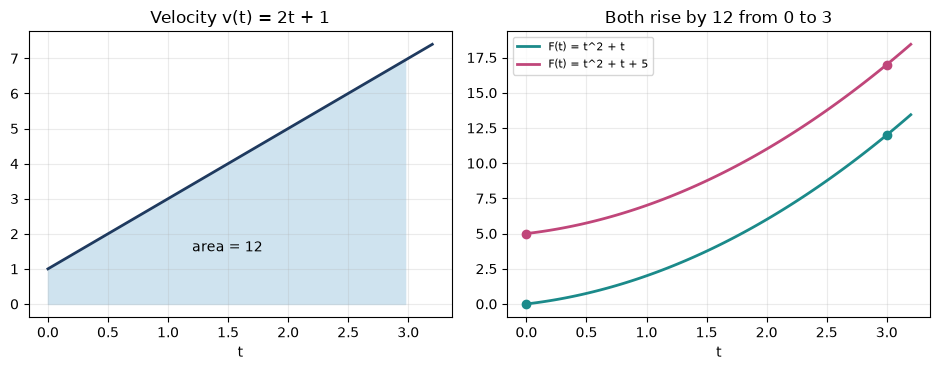

In [7]:
ts = np.linspace(0, 3.2, 100)
upper = 3
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
a1.plot(ts, 2*ts + 1, color=NAVY, lw=2)
m = ts <= upper
a1.fill_between(ts[m], 0, 2*ts[m] + 1, color="#cfe3ef"); a1.text(1.2, 1.5, "area = 12")
a1.set_title("Velocity v(t) = 2t + 1"); a1.set_xlabel("t"); a1.grid(alpha=0.25)
for sh, col in ((0, TEAL), (5, PINK)):
    a2.plot(ts, ts**2 + ts + sh, color=col, lw=2, label=f"F(t) = t^2 + t + {sh}" if sh else "F(t) = t^2 + t")
    a2.plot([0, upper], [sh, 12 + sh], "o", color=col)
a2.legend(fontsize=8); a2.set_title("Both rise by 12 from 0 to 3"); a2.set_xlabel("t"); a2.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**What this shows.** The shaded area on the left and the rise of $F$ on the right are the same number, 12. Shifting $F$ up moves both endpoint values together, so their difference stays put. Before using an antiderivative, differentiate it and confirm it returns the rate. Then subtract and check the answer against the graph.

**Where it stops working.** This needs a continuous velocity on a closed interval. Because $v$ stays positive here, distance equals displacement; that would fail if $v$ changed sign (which is the next demonstration).

## Demonstration 4: A velocity that crosses zero

**Question.** When velocity changes sign at $t = 2$, why do displacement and distance part ways?

$$v(t) = 2t - 4 \qquad\qquad F(t) = t^2 - 4t$$

- $v(t)$ is velocity in meters per second: negative before 2 seconds and positive after.
- $F(t) = t^2 - 4t$ is an antiderivative.
- The traveler starts at 10 meters.

**Predict first:** stop the clock at $t = 4$. What are the displacement and the distance?

Starting value: stop at $t = 5$.

In [8]:
F = lambda t: t**2 - 4*t
T = 5
print(f"F({T}) = {T}^2 - 4 x {T} = {T**2} - {4*T} = {F(T)}")
print(f"Displacement: F({T}) - F(0) = {F(T)} - {F(0)} = {F(T) - F(0)} meters")
neg = -(F(2) - F(0))
pos = F(T) - F(2)
print(f"Negative piece, sign flipped: -[F(2) - F(0)] = -[({F(2)}) - 0] = {neg}")
print(f"Positive piece: F({T}) - F(2) = {F(T)} - ({F(2)}) = {pos}")
print(f"Distance: {neg} + {pos} = {neg + pos} meters")
print(f"Ending position from 10 meters: 10 + {F(T) - F(0)} = {10 + F(T) - F(0)} meters")
print()
print("All menu states:")
for T in (1, 2, 4, 5):
    tt = min(T, 2)
    n = -(F(tt) - F(0)); p = max(0, F(T) - F(2)) if T > 2 else 0
    print(f"  stop at {T}: displacement F({T}) - F(0) = {F(T)}; distance {n}" + (f" + {p}" if T > 2 else "") + f" = {n + p}; end 10 + {par(F(T))} = {10 + F(T)}")

F(5) = 5^2 - 4 x 5 = 25 - 20 = 5
Displacement: F(5) - F(0) = 5 - 0 = 5 meters
Negative piece, sign flipped: -[F(2) - F(0)] = -[(-4) - 0] = 4
Positive piece: F(5) - F(2) = 5 - (-4) = 9
Distance: 4 + 9 = 13 meters
Ending position from 10 meters: 10 + 5 = 15 meters

All menu states:
  stop at 1: displacement F(1) - F(0) = -3; distance 3 = 3; end 10 + (-3) = 7
  stop at 2: displacement F(2) - F(0) = -4; distance 4 = 4; end 10 + (-4) = 6
  stop at 4: displacement F(4) - F(0) = 0; distance 4 + 4 = 8; end 10 + 0 = 10
  stop at 5: displacement F(5) - F(0) = 5; distance 4 + 9 = 13; end 10 + 5 = 15


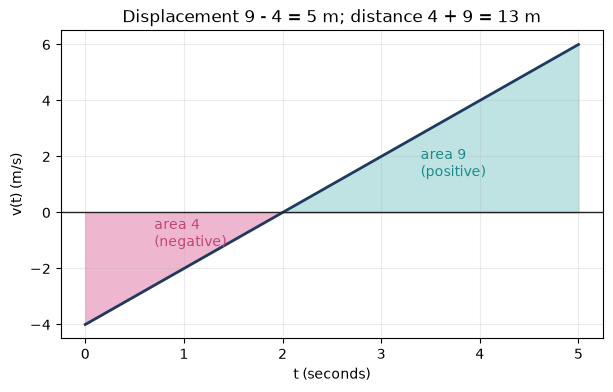

In [9]:
ts = np.linspace(0, 5, 200)
fig, ax = new_fig(7, 4)
ax.plot(ts, 2*ts - 4, color=NAVY, lw=2)
m1 = ts <= 2; m2 = ts >= 2
ax.fill_between(ts[m1], 0, 2*ts[m1] - 4, color="#efb6cf")
ax.fill_between(ts[m2], 0, 2*ts[m2] - 4, color="#bfe3e3")
ax.axhline(0, color=INK, lw=1)
ax.text(0.7, -1.2, "area 4\n(negative)", color=PINK); ax.text(3.4, 1.3, "area 9\n(positive)", color=TEAL)
ax.set_xlabel("t (seconds)"); ax.set_ylabel("v(t) (m/s)")
ax.set_title("Displacement 9 - 4 = 5 m; distance 4 + 9 = 13 m"); plt.show()

**What this shows.** The signed pieces add with their signs for displacement: $-4 + 9 = 5$. For distance, the negative piece has its sign flipped before adding, so nothing cancels: $4 + 9 = 13$. When a rate can change sign, find where it does, split the interval there, and add the sizes of the pieces.

**Where it stops working.** This assumes a continuous velocity on one line, with a start at 10 meters. A zero of $v$ is only a candidate for a reversal; the sign on each side decides.

## Practice

Try each one on paper first, then open the answer to compare.

**1.** Starting at 10 with velocities $+3$ then $-5$, where does the traveler end, and how far did they go?

<details><summary>Show answer</summary>

Displacement: $+3 + (-5) = -2$, so $s(2) = 10 + (-2) = 8$. Distance: $3 + 5 = 8$ units.

</details>

**2.** At $x = 1$ with $h = 0.5$ for $f(t) = 2t + 1$, what does the strip add, and what is strip $/ h$?

<details><summary>Show answer</summary>

$A(1.5) - A(1) = 3.75 - 2 = 1.75$, and $1.75 / 0.5 = 3.5$, which is $f(1) = 3$ plus $h = 0.5$.

</details>

**3.** What is the displacement from $t = 0$ to $t = 2$ for $v(t) = 2t + 1$?

<details><summary>Show answer</summary>

$F(2) - F(0) = (2^2 + 2) - 0 = 6$ length units. Graph check: $\dfrac{1 + 5}{2} \times 2 = 6$.

</details>

**4.** For $v(t) = 2t - 4$, stopping at $t = 3$, what are the displacement and the distance?

<details><summary>Show answer</summary>

Displacement: $F(3) - F(0) = (3^2 - 4 \times 3) - 0 = -3$ meters. Distance: $4 + [F(3) - F(2)] = 4 + [(-3) - (-4)] = 4 + 1 = 5$ meters.

</details>